# Exploring the naval propulsion data

**Goal:** understand the data before modeling. The question is whether the sensor readings can predict how worn the compressor and turbine are (the two decay columns, where 1.00 is healthy and lower means more wear).

The data is 11,934 simulated rows with 16 sensor columns and 2 decay columns, and no missing values.

In [ ]:
import pandas as pd

cols = [
    "lever_position",
    "ship_speed_knots",
    "gas_turbine_shaft_torque_kNm",
    "gas_turbine_rpm",
    "gas_generator_rpm",
    "starboard_propeller_torque_kN",
    "port_propeller_torque_kN",
    "hp_turbine_exit_temp_C",
    "gt_compressor_inlet_air_temp_C",
    "gt_compressor_outlet_air_temp_C",
    "hp_turbine_exit_pressure_bar",
    "gt_compressor_inlet_air_pressure_bar",
    "gt_compressor_outlet_air_pressure_bar",
    "gas_turbine_exhaust_gas_pressure_bar",
    "turbine_injection_control_pct",
    "fuel_flow_kg_per_s",
    "gt_compressor_decay_state",
    "gt_turbine_decay_state",
]

df = pd.read_csv("../data/raw/data.csv", header=0, names=cols)
df.head()


,lever_position,ship_speed_knots,gas_turbine_shaft_torque_kNm,gas_turbine_rpm,gas_generator_rpm,starboard_propeller_torque_kN,port_propeller_torque_kN,hp_turbine_exit_temp_C,gt_compressor_inlet_air_temp_C,gt_compressor_outlet_air_temp_C,hp_turbine_exit_pressure_bar,gt_compressor_inlet_air_pressure_bar,gt_compressor_outlet_air_pressure_bar,gas_turbine_exhaust_gas_pressure_bar,turbine_injection_control_pct,fuel_flow_kg_per_s,gt_compressor_decay_state,gt_turbine_decay_state
0,1.138,3.0,289.964,1349.489,6677.380,7.584,7.584,464.006,288.0,550.563,1.096,0.998,5.947,1.019,7.137,0.082,0.95,0.975
1,2.088,6.0,6960.180,1376.166,6828.469,28.204,28.204,635.401,288.0,581.658,1.331,0.998,7.282,1.019,10.655,0.287,0.95,0.975
2,3.144,9.0,8379.229,1386.757,7111.811,60.358,60.358,606.002,288.0,587.587,1.389,0.998,7.574,1.020,13.086,0.259,0.95,0.975
3,4.161,12.0,14724.395,1547.465,7792.630,113.774,113.774,661.471,288.0,613.851,1.658,0.998,9.007,1.022,18.109,0.358,0.95,0.975
4,5.140,15.0,21636.432,1924.313,8494.777,175.306,175.306,731.494,288.0,645.642,2.078,0.998,11.197,1.026,26.373,0.522,0.95,0.975


In [ ]:
print(df.shape)
print(df.isna().sum().sum())
print(df.dtypes)

(11934, 18)
0
lever_position                           float64
ship_speed_knots                         float64
gas_turbine_shaft_torque_kNm             float64
gas_turbine_rpm                          float64
gas_generator_rpm                        float64
starboard_propeller_torque_kN            float64
port_propeller_torque_kN                 float64
hp_turbine_exit_temp_C                   float64
gt_compressor_inlet_air_temp_C           float64
gt_compressor_outlet_air_temp_C          float64
hp_turbine_exit_pressure_bar             float64
gt_compressor_inlet_air_pressure_bar     float64
gt_compressor_outlet_air_pressure_bar    float64
gas_turbine_exhaust_gas_pressure_bar     float64
turbine_injection_control_pct            float64
fuel_flow_kg_per_s                       float64
gt_compressor_decay_state                float64
gt_turbine_decay_state                   float64
dtype: object


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

targets = ["gt_compressor_decay_state", "gt_turbine_decay_state"]

df.nunique()

lever_position                               9
ship_speed_knots                             9
gas_turbine_shaft_torque_kNm             11430
gas_turbine_rpm                           3888
gas_generator_rpm                        11834
starboard_propeller_torque_kN             4286
port_propeller_torque_kN                  4286
hp_turbine_exit_temp_C                   11772
gt_compressor_inlet_air_temp_C               1
gt_compressor_outlet_air_temp_C          11506
hp_turbine_exit_pressure_bar               524
gt_compressor_inlet_air_pressure_bar         1
gt_compressor_outlet_air_pressure_bar     4209
gas_turbine_exhaust_gas_pressure_bar        19
turbine_injection_control_pct             8496
fuel_flow_kg_per_s                         696
gt_compressor_decay_state                   51
gt_turbine_decay_state                      26
dtype: int64

### Correlation heatmap

- Almost every sensor correlates 0.9 to 1.0 with every other sensor and with lever position because the throttle drives the whole engine.
- Both decay columns sit near 0 with everything, including each other.
- The compressor inlet air temperature and pressure columns are blank because they never change.

The throttle's effect is so large it hides the wear signal in this view. The two constant columns should be dropped before modeling.

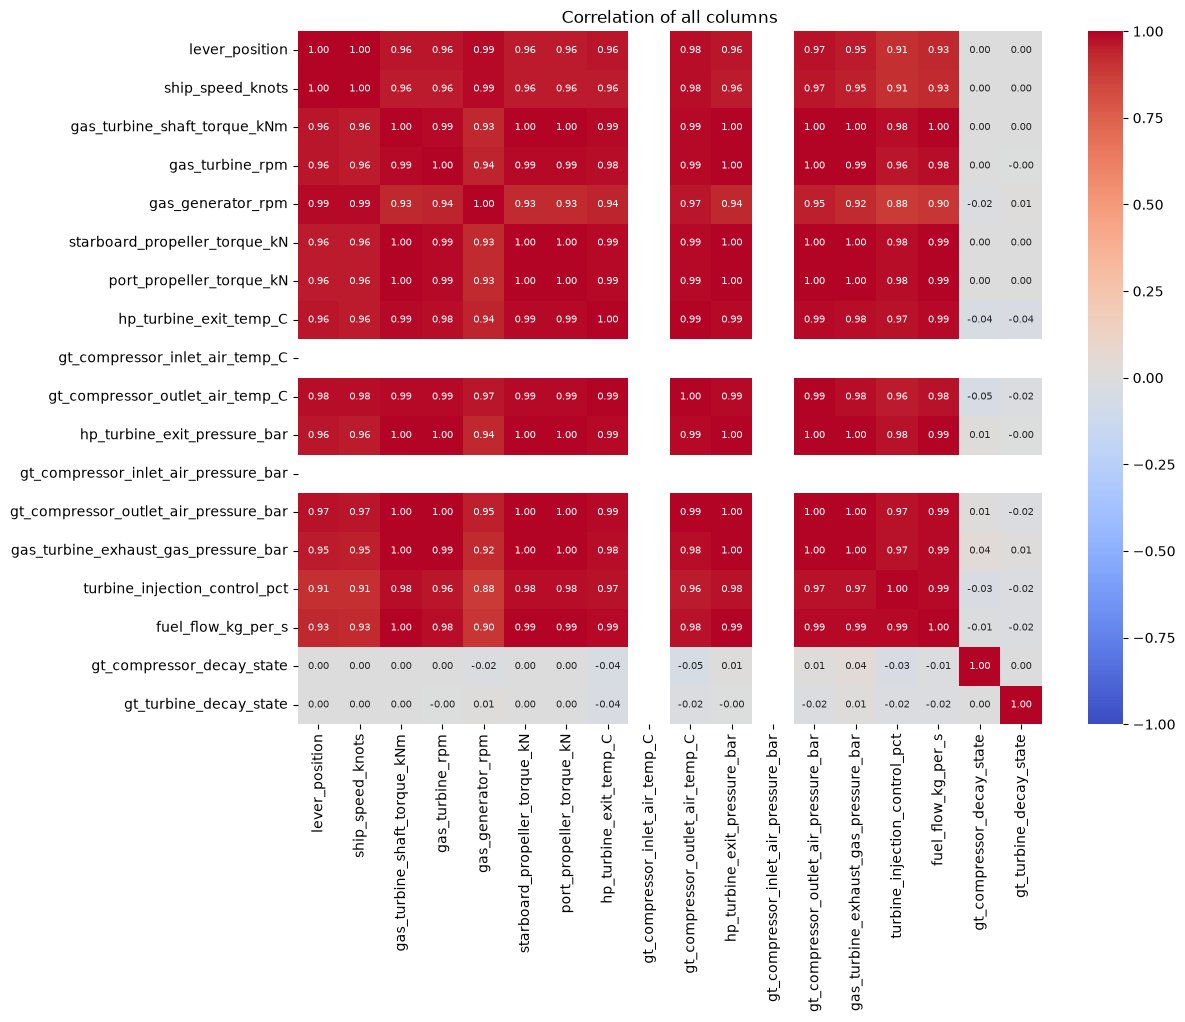

In [14]:
corr = df.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f",
            annot_kws={"size": 7}, vmin=-1, vmax=1, cmap="coolwarm")

plt.title("Correlation of all columns")
plt.savefig("../reports/figures/01_correlation_heatmap.png", dpi=150, bbox_inches="tight")

### Ship speed vs fuel flow

- Each dot is one row and the vertical stripes are the 9 lever positions.
- r = 0.93, and fuel flow climbs faster at higher speeds, so the curve bends upward. The stripes at low speeds are taller, meaning there's more fuel variation at the same speed.
- The throttle has a big effect on fuel use, but the wear is the smaller variation inside each stripe.

0.9278150228106308


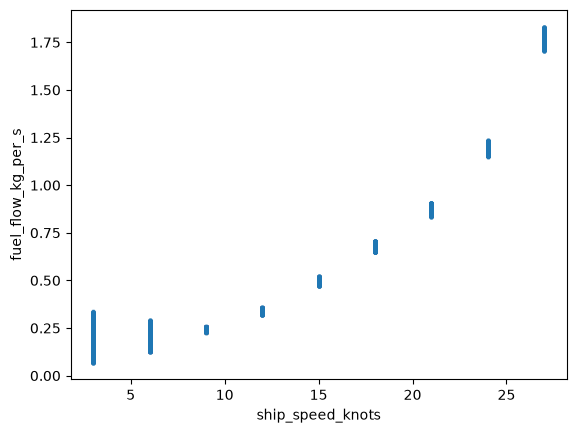

In [16]:
x, y = "ship_speed_knots", "fuel_flow_kg_per_s"
plt.scatter(df[x], df[y], s=5, alpha=0.3)
plt.xlabel(x)
plt.ylabel(y)
print(df[x].corr(df[y]))

plt.savefig("../reports/figures/02_speed_vs_fuel_flow.png", dpi=150, bbox_inches="tight")

### Sensors vs wear at one throttle setting

This shows the same correlations, but only for rows at the highest lever position (1,326 rows). Holding the throttle fixed removes its effect, meaning the effect of the wear is much more visible.

- Compressor wear: compressor outlet air temperature (-0.98), gas generator rpm (-0.94), HP turbine exit temperature (-0.93)
- Turbine wear: gas turbine shaft torque (+0.92), compressor outlet air pressure (-0.90)
- NaN rows are columns that don't vary within one throttle setting.
- The decay value drops as wear increases. A negative number means the sensor rises with more wear, and a positive number means it falls.

In [6]:
sub = df[df["lever_position"] == df["lever_position"].max()]
print(len(sub))
sub.corr()[targets].drop(targets)

1326


,gt_compressor_decay_state,gt_turbine_decay_state
lever_position,NaN,NaN
ship_speed_knots,NaN,NaN
gas_turbine_shaft_torque_kNm,-0.373390,0.921058
gas_turbine_rpm,-0.557104,0.507941
gas_generator_rpm,-0.935041,0.353690
starboard_propeller_torque_kN,-0.138305,0.279258
port_propeller_torque_kN,-0.138305,0.279258
hp_turbine_exit_temp_C,-0.928653,-0.370613
gt_compressor_inlet_air_temp_C,NaN,NaN
gt_compressor_outlet_air_temp_C,-0.978387,-0.205871


### Compressor outlet air temperature vs compressor wear

On the left, it shows all throttle settings mixed into one chart. On the right, it's one throttle setting colored by turbine wear.

- On the left, there are separate horizontal bands. There is one per throttle setting, ranging from about 550 to 800 degrees. Inside each band, there is a slight downward slope.
- On the right, there's a clear slope. As the decay value drops from 1.00 to 0.95, the air leaving the compressor gets about 17 degrees hotter. Turbine wear (color) shifts it slightly as well.
- The wear is clearly visible once throttle is held fixed. A worn compressor is less efficient, so it heats the air more.

gt_compressor_outlet_air_temp_C


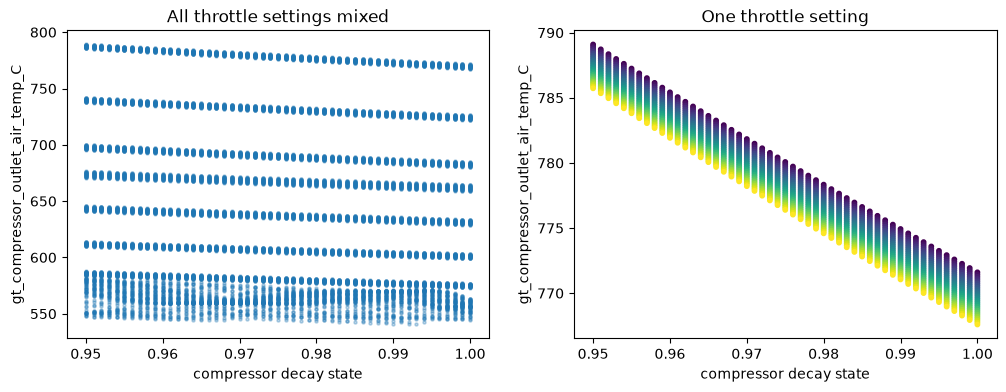

In [17]:
sensor = sub.corr()["gt_compressor_decay_state"].drop(targets).abs().idxmax()
print(sensor)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(df["gt_compressor_decay_state"], df[sensor], s=5, alpha=0.3)
axes[0].set_title("All throttle settings mixed")

axes[1].scatter(sub["gt_compressor_decay_state"], sub[sensor],
                c=sub["gt_turbine_decay_state"], s=10)
axes[1].set_title("One throttle setting")

for ax in axes:
    ax.set_xlabel("compressor decay state")
    ax.set_ylabel(sensor)

fig.savefig("../reports/figures/03_wear_signal_throttle_fixed.png", dpi=150, bbox_inches="tight")

### Shaft torque vs turbine wear

- As the decay value drops, the torque also drops, showing a linear correlation. The torque drops by around 25 kNm when the decay value goes from 1 to 0.975. The colors show compressor wear, with the purple dots, which more compressor wear, sit higher than the yellow ones, by roughly 10 kNm.
- This sensor tracks turbine wear, with a smaller compressor effect on top.

Text(0, 0.5, 'gas_turbine_shaft_torque_kNm')

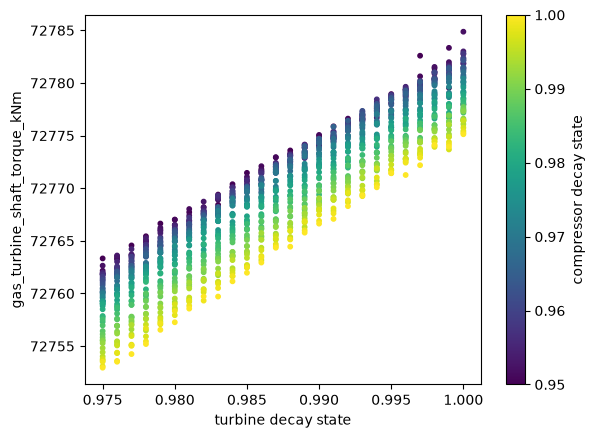

In [8]:
plt.scatter(sub["gt_turbine_decay_state"], sub["gas_turbine_shaft_torque_kNm"],
            c=sub["gt_compressor_decay_state"], s=10)
plt.colorbar(label="compressor decay state")
plt.xlabel("turbine decay state")
plt.ylabel("gas_turbine_shaft_torque_kNm")

### Decay vs sensors (one throttle setting)

Each row is a sensor, and the columns (from left to right) are compressor decay and turbine decay.
- Compressor outlet air temperature and HP turbine exit temperature have a tight slope against compressor decay and a wide band against turbine decay.
- Shaft torque has a clean slope against turbine decay and a messy cloud against compressor decay.
- Gas generator rpm and compressor outlet air pressure show slopes in both panels. For rpm, they point in opposite directions.
- Exhaust gas pressure only takes 4 values, so it shows steps instead of a smooth slope. It's hard to see a pattern in it.

From this, the most visible ways to see compressor wear in effect are compressor outlet air temperature and HP turbine exit temperature. The most visible way for turbine wear are shaft torque and compressor outlet air pressure. Since most sensors are affected by both wear types at once, a model using several sensors together can separate the two better than any single sensor.

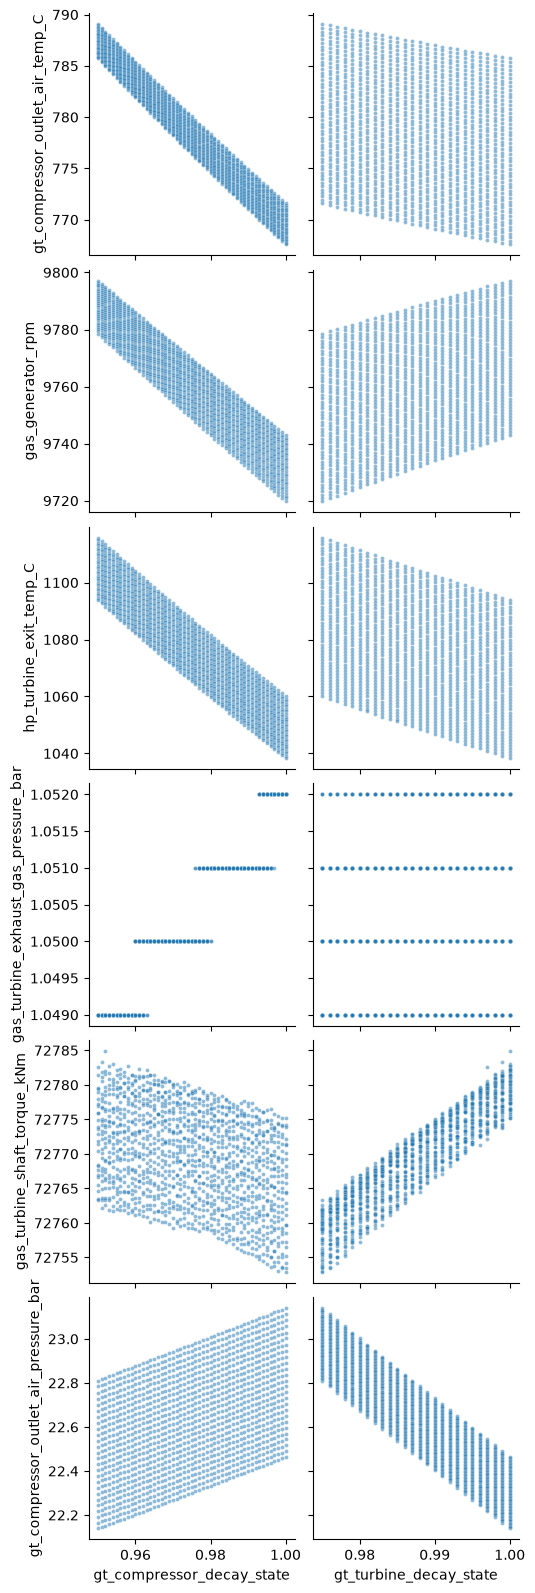

In [18]:
sensors = ["gt_compressor_outlet_air_temp_C", "gas_generator_rpm",
           "hp_turbine_exit_temp_C", "gas_turbine_exhaust_gas_pressure_bar",
           "gas_turbine_shaft_torque_kNm", "gt_compressor_outlet_air_pressure_bar"]

g = sns.pairplot(sub, x_vars=targets, y_vars=sensors, height=2.7,
                 plot_kws={"s": 8, "alpha": 0.5})
g.savefig("../reports/figures/04_decay_vs_sensors_matrix.png", dpi=150, bbox_inches="tight")

### Generator rpm check

Average gas generator rpm was about 9788 at the most worn compressor level (0.95) and about 9732 at healthy (1.00). More wear means the generator spins faster to do the same job. The effect is small (under 1%) but perfectly consistent.

In [10]:
sub.groupby("gt_compressor_decay_state")["gas_generator_rpm"].mean().iloc[[0, -1]]

gt_compressor_decay_state
0.95    9788.022115
1.00    9731.662308
Name: gas_generator_rpm, dtype: float64

## Findings so far
- Throttle (lever position) controls almost everything and is independent of wear.
- Wear shows up in the sensors but only when you compare rows at the same throttle setting.
- Different sensors track compressor wear and turbine wear.
- Two columns are constant and will be dropped.
- Data is simulated and noise-free, so real-world results would likely be messier.